---
title: Laboratory Exercise (Model Inference on Custom Dataset)
---

# Laboratory Exercise: Image Classification Using Pre-trained Models

**Name:** Rosemarie Ann S. Bajao  
**Course:** BS Data Science  
**Activity:** Model Inference on Custom Dataset

---

## Overview

This notebook uses a custom image dataset containing laptops and cell phones to evaluate and compare five pre-trained image classification models from torchvision.models. The models are used directly without additional training.

The workflow includes creating a custom PyTorch Dataset, using a DataLoader to load the images in batches, running five pre-trained models on the dataset, and comparing their performance using accuracy, precision, recall, and F1-score.

**Import Libraries**

In [1]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
os.listdir('dataset')

['0', '1']

In [3]:
root = 'dataset'

In [4]:
data_dict = {'X': [], 'y': []}

for cls in sorted(os.listdir(root)):
    cls_path = os.path.join(root, cls)

    if not os.path.isdir(cls_path):
        continue

    for img in sorted(os.listdir(cls_path)):
        img_path = os.path.join(cls_path, img)
        data_dict['X'].append(img_path)
        data_dict['y'].append(int(cls))

data = pd.DataFrame(data_dict)
data

,X,y
0,dataset\0\acer nitro 16.jpg,0
1,dataset\0\asus rog strix g 2019.jpg,0
2,dataset\0\legion 5 pro.jpg,0
3,dataset\1\honor x6.jpg,1
4,dataset\1\huawei phone.png,1
5,dataset\1\vivo v30e.png,1


## Custom PyTorch `Dataset` Class

Loads the images from the dataset/0 (laptop) and dataset/1 (cell phone) folders and returns each image together with its correct label. The images are prepared later using the preprocessing required by each pre-trained model.


In [7]:
class CustomDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row['X']).convert('RGB')
        label = row['y']
        return image, label

custom_dataset = CustomDataset(data)
print(f"Total images: {len(custom_dataset)}")

Total images: 6


## `DataLoader` for Batching

The images may have different sizes, so the DataLoader uses a custom collate_fn to group the images into batches without changing them yet. The required preprocessing is applied later for each pre-trained model.

In [8]:
def collate_fn(batch):
    images, labels = zip(*batch)
    return list(images), list(labels)

batch_size = 4
dataloader = DataLoader(custom_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

print(f"Number of batches: {len(dataloader)}")

Number of batches: 2


## Define Five Pre-trained Models

Five different pre-trained classification models from torchvision.models are compared, with differences in their architecture and complexity:

In [9]:
LAPTOP_IDX = 620   # "laptop" in ImageNet's 1000 classes
PHONE_IDX = 487    # "cellular telephone" in ImageNet's 1000 classes

model_configs = {
    "ResNet18":       (models.resnet18,        models.ResNet18_Weights.DEFAULT),
    "ResNet50":       (models.resnet50,        models.ResNet50_Weights.DEFAULT),
    "MobileNetV2":    (models.mobilenet_v2,    models.MobileNet_V2_Weights.DEFAULT),
    "VGG16":          (models.vgg16,           models.VGG16_Weights.DEFAULT),
    "EfficientNetB0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.DEFAULT),
}

print("Models to compare:", list(model_configs.keys()))

Models to compare: ['ResNet18', 'ResNet50', 'MobileNetV2', 'VGG16', 'EfficientNetB0']


## Run Inference for Each Model

Each image is processed using the preprocessing required by the current model. Since the dataset contains only laptops and cell phones, the model compares its scores for the two corresponding ImageNet classes: laptop (620) and cellular telephone (487). The class with the higher score is used as the prediction.

The pre-trained models normally predict among 1000 ImageNet classes. For this activity, only the two relevant classes—laptop (620) and cellular telephone (487)—are considered. The model compares the scores of these two classes, and the one with the higher score becomes the predicted label. This allows the pre-trained models to be used directly on the custom dataset without additional training.

In [10]:
all_results = {}

for model_name, (model_fn, weights) in model_configs.items():
    print(f"Running {model_name}...")
    model = model_fn(weights=weights)
    model.eval()
    transform = weights.transforms()

    records = []
    for images, labels in dataloader:
        for img, true_label in zip(images, labels):
            x = transform(img).unsqueeze(0)
            with torch.no_grad():
                logits = model(x)

            laptop_score = logits[0, LAPTOP_IDX].item()
            phone_score = logits[0, PHONE_IDX].item()
            predicted_label = 0 if laptop_score > phone_score else 1

            records.append({
                "True Label": true_label,
                "Predicted Label": predicted_label,
                "Correct": true_label == predicted_label
            })

    all_results[model_name] = pd.DataFrame(records)

print("\nInference complete for all 5 models.")

Running ResNet18...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


Running ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 147MB/s]


Running MobileNetV2...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 90.3MB/s]


Running VGG16...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 129MB/s]


Running EfficientNetB0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 121MB/s] 



Inference complete for all 5 models.


## Compute Accuracy, Precision, Recall, and F1-score for Each Model

In [11]:
metrics_summary = []

for model_name, df in all_results.items():
    y_true = df["True Label"]
    y_pred = df["Predicted Label"]

    metrics_summary.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    })

comparison_df = pd.DataFrame(metrics_summary).set_index("Model")
comparison_df = comparison_df.round(3)
comparison_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
ResNet18,0.833,1.0,0.667,0.8
ResNet50,1.000,1.0,1.000,1.0
MobileNetV2,1.000,1.0,1.000,1.0
VGG16,0.833,1.0,0.667,0.8
EfficientNetB0,0.667,1.0,0.333,0.5


## Visualize the Comparison

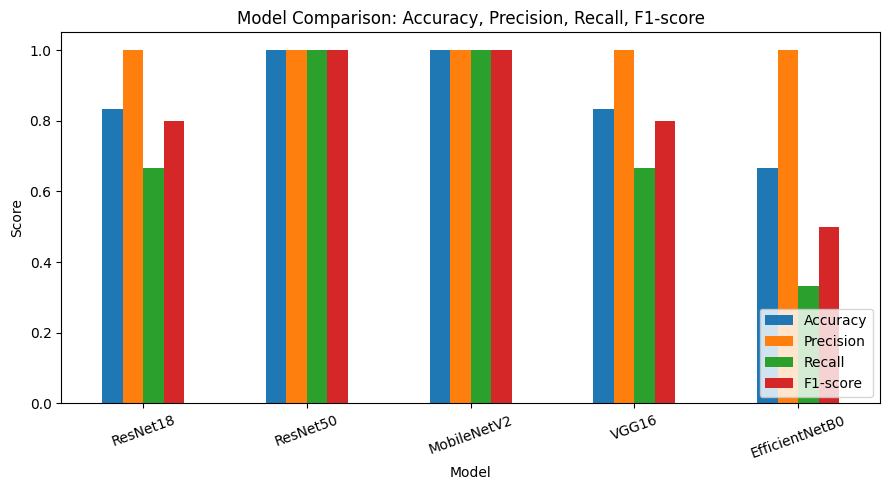

In [12]:
comparison_df.plot(kind='bar', figsize=(9, 5))
plt.title("Model Comparison: Accuracy, Precision, Recall, F1-score")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Per-Class Accuracy Breakdown (One Model with 100% Observed Accuracy)

This section shows the per-class accuracy for one of the models that achieved 100% accuracy on this specific dataset. ResNet50 was selected for the breakdown.

In [13]:
best_model_name = comparison_df["Accuracy"].idxmax()
print(f"Selected model for per-class accuracy breakdown: {best_model_name}")

best_df = all_results[best_model_name].copy()
best_df["True Label Name"] = best_df["True Label"].map({0: "Laptop", 1: "Cell phone"})

class_results = (
    best_df
    .groupby("True Label Name")["Correct"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "Correct", "count": "Total"})
)
class_results["Accuracy"] = class_results["Correct"] / class_results["Total"]
class_results

Selected model for per-class accuracy breakdown: ResNet50


,Correct,Total,Accuracy
True Label Name,,,
Cell phone,3,3,1.0
Laptop,3,3,1.0


## Analysis and Conclusion

The five pre-trained models were evaluated on the custom dataset using accuracy, precision, recall, and F1-score. The resulting values are shown in the comparison table and chart above.

Since the inference process compares only the scores of the two selected ImageNet classes (see the methodology note above), every image is assigned to either laptop or cell phone, with no option for the model to predict anything else. Therefore, the reported metrics reflect each model's ability to distinguish between these two specific classes, rather than its full 1000-class ImageNet classification performance. Any misclassification or recall error means that the model's score for the incorrect one of these two classes happened to be higher; it does not mean that the model recognized the image as something entirely unrelated.

The models produced different results on this particular dataset. The comparison table and visualization show the observed differences in accuracy, precision, recall, and F1-score across the five models. Differences in performance across the five models may be related to several factors:

- **Model architecture:** The five models use different architectures, which may affect how they represent and classify visual features. These architectural differences may contribute to differences in performance on the custom dataset.
- **Model complexity:** More complex models may capture more detailed visual features, but they can also require more computational resources. Simpler models may have different performance characteristics and may be more practical when computational resources are limited.
- **Preprocessing requirements:** Each model expects a specific input size and normalization, handled here through each model's own `weights.transforms()`. Differences in how sensitive a model is to image quality, lighting, or background may still affect its predictions even when preprocessing is handled correctly.
- **Similarity to ImageNet's original training data:** Since all five models were pretrained on ImageNet's natural, real-world photos, a model's performance may depend on how visually similar the custom dataset's images are to typical ImageNet photos, versus more stylized, product-photo-style images.

**Important limitation:** This dataset contains only 3 images per class (6 images total). With such a small sample size, a single misclassification changes accuracy by roughly 16.7 percentage points. This means a result such as "100% accuracy" should be understood specifically as *100% accuracy on this particular 6-image custom dataset*, and not interpreted as a general claim about that model's real-world accuracy. A larger and more varied dataset would be needed to draw more reliable conclusions about how the models perform on a broader set of images.

**Conclusion:** This exercise demonstrates how pre-trained image classification models can be applied directly to a custom dataset without additional training when the target categories are available in the models' original class set. Because the dataset contains only six images, the results should be interpreted as observations from this particular dataset rather than as a general measure of model performance. Any comparison between the models should therefore be limited to the dataset and conditions tested in this activity.